## Datasci 530 - Assignment 5
### Predicting the 'class' label of Iris plant data

Joelle Millar
November 2026


## Overview

This project investigates the predictive performance of four machine learning approaches for classifying Iris flower species: Support Vector Machines (SVMs), Random Forests, Neural Networks and Naïve Bayes. The analysis uses the Iris dataset from the UCI Machine Learning Repository, which contains measurements of sepal and petal dimensions for three Iris species.

Models are evaluated using stratified 10-fold cross-validation, with accuracy, macro-averaged precision and macro-averaged F1-score used to compare predictive performance. An SVM model is additionally optimised through a grid search over alternative hyperparameter combinations. A separate test dataset is retained to assess the predictive performance of the selected model on previously unseen observations.

The final section explores relationships between flower characteristics and species to investigate which features appear most useful for distinguishing between the three classes.

### Key Findings

The default SVM model achieved the highest cross-validation accuracy.

The tuned SVM did not improve on the default SVM. 

The default SVM model achieved the strongest macro F1-score.

The default SVM model acheived 96.67% accuracy on the classified the test observations.

The additional analysis of flower characteristics showed that petal length and petal width are particularly useful for distinguishing between the three species. This provides an intuitive explanation for the strong classification performance observed across the models.

### Set Up, Data Cleaning & Data Descriptions

The Iris dataset contains 150 observations and four numerical explanatory variables: sepal length, sepal width, petal length and petal width. The target variable, `Class`, identifies the flower species.

There are three classes: Iris Setosa, Iris Versicolor and Iris Virginica. Each class contains 50 observations, meaning the dataset is perfectly balanced, with each species accounting for approximately one-third of the sample.

The dataset was checked for missing values and duplicate observations. The four explanatory variables are numerical, while the target variable is categorical.

The balanced class distribution means that accuracy is a useful initial measure of predictive performance. However, macro-averaged precision and F1-score are also considered to assess performance across all three species without giving greater weight to any particular class.

In [54]:
# Import Libraries
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# Load Modules, Functions, Objects
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.naive_bayes import GaussianNB

from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.model_selection import GridSearchCV

from sklearn.metrics import classification_report
from sklearn.metrics import confusion_matrix
from sklearn.metrics import accuracy_score


Number of rows: 150
Number of features: 4
Number of classes: 3

Missing values:
Sepal Length    0
Sepal Width     0
Petal Length    0
Petal Width     0
Class           0
dtype: int64

Number of duplicate rows: 3


,Count,Proportion
Class,,
Iris-setosa,50,0.3333
Iris-versicolor,50,0.3333
Iris-virginica,50,0.3333


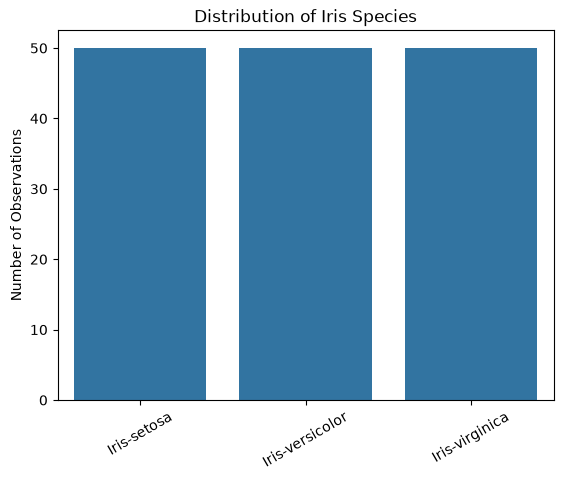

In [55]:
# Load dataset
col_names = [
    'Sepal Length',
    'Sepal Width',
    'Petal Length',
    'Petal Width',
    'Class'
]
iris_data = pd.read_csv(
    "data_raw/iris/iris.data",
    names=col_names
)

# Dataset dimensions
print(f"Number of rows: {iris_data.shape[0]}")
print(f"Number of features: {iris_data.shape[1] - 1}")
print(f"Number of classes: {iris_data['Class'].nunique()}")

# Check missing values
print("\nMissing values:")
print(iris_data.isnull().sum())

# Check duplicate observations
print("\nNumber of duplicate rows:", iris_data.duplicated().sum())


# Class distribution
class_distribution = pd.DataFrame({
    'Count': iris_data['Class'].value_counts(),
    'Proportion': iris_data['Class'].value_counts(normalize=True)
})

display(class_distribution.round(4))

# Bar Chart for Distribution
sns.countplot(data=iris_data, x='Class')

plt.title('Distribution of Iris Species')
plt.ylabel('Number of Observations')
plt.xlabel('')
plt.xticks(rotation=30)
plt.show()

### Comparison of different ML methods (SVMs, Random Forests, Neural Networks, Naïve Bayes)

Prepare the data, separating exploratory variables (X) from the target variable (y) 

In [56]:
# Separate explanatory variables and target
X = iris_data.drop('Class', axis=1)
y = iris_data['Class']

print(f'X shape: {X.shape} | y shape: {y.shape}')

# Split into training and testing datasets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=1,
    stratify=y
)

print(f'Training observations: {len(X_train)}')
print(f'Testing observations: {len(X_test)}')

X shape: (150, 4) | y shape: (150,)
Training observations: 120
Testing observations: 30


Build the models, using default tuning parameters for all methods and a scaler for SVM and neural networks because their performance can be affected by differences in feature magnitudes.

In [57]:
# Define the four models, using a seed to make the results reproducible
models = {
    'SVM': Pipeline([
        ('scaler', StandardScaler()),
        ('model', SVC())
    ]),

    'Random Forest': RandomForestClassifier(
        random_state=1
    ),

    'Neural Network': Pipeline([
        ('scaler', StandardScaler()),
        ('model', MLPClassifier(random_state=1))
    ]),

    'Naive Bayes': GaussianNB()
}

Evaluation of the predictive performance using 10-fold cross-validation.

In [58]:
# Outer cross-validation: model evaluation
kfold = StratifiedKFold(
    n_splits=10,
    shuffle=True,
    random_state=1
)

# Inner cross-validation: SVM tuning
inner_kfold = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=1
)

# Evaluation metrics
scoring = {
    'accuracy': 'accuracy',
    'precision': 'precision_macro',
    'recall': 'recall_macro',
    'f1': 'f1_macro'
}

# Evaluate each model
results = []

for name, model in models.items():

    cv_results = cross_validate(
        model,
        X_train,
        y_train,
        cv=kfold,
        scoring=scoring
    )

    results.append({
        'Model': name,
        'Accuracy': cv_results['test_accuracy'].mean(),
        'Accuracy SD': cv_results['test_accuracy'].std(),
        'Precision': cv_results['test_precision'].mean(),
        'Recall': cv_results['test_recall'].mean(),
        'F1-score': cv_results['test_f1'].mean()
    })

results_df = pd.DataFrame(results)

display(
    results_df.sort_values(
        by='Accuracy',
        ascending=False
    ).round(4)
)

/opt/anaconda3/lib/python3.14/site-packages/sklearn/neural_network/_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (200) reached and the optimization hasn't converged yet.
  warnings.warn(
/opt/anaconda3/lib/python3.14/site-packages/sklearn/neural_network/_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (200) reached and the optimization hasn't converged yet.
  warnings.warn(
/opt/anaconda3/lib/python3.14/site-packages/sklearn/neural_network/_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (200) reached and the optimization hasn't converged yet.
  warnings.warn(
/opt/anaconda3/lib/python3.14/site-packages/sklearn/neural_network/_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (200) reached and the optimization hasn't converged yet.
  warnings.warn(
/opt/anaconda3/lib/python3.14/site-packages/sklearn/neural_network/_

,Model,Accuracy,Accuracy SD,Precision,Recall,F1-score
0,SVM,0.9583,0.0559,0.9650,0.9583,0.9578
3,Naive Bayes,0.9500,0.0764,0.9556,0.9500,0.9492
1,Random Forest,0.9417,0.0534,0.9556,0.9417,0.9399
2,Neural Network,0.9333,0.0816,0.9406,0.9333,0.9324


Tune the Parameters for SVM

In [59]:
# Define SVM pipeline
svm_pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('model', SVC())
])

# Define parameter grid
param_grid = {
    'model__C': [0.1, 1, 10, 100, 1000],
    'model__gamma': ['scale', 0.01, 0.1, 1, 10]
}

# Grid search using inner cross-validation
svm_grid = GridSearchCV(
    estimator=svm_pipeline,
    param_grid=param_grid,
    cv=inner_kfold,
    scoring='accuracy',
    refit=True,
    n_jobs=-1
)

# Fit grid search
svm_grid.fit(X_train, y_train)

# Display best parameters and score
print("Best parameters:", svm_grid.best_params_)
print("Best cross-validation accuracy:", svm_grid.best_score_)

svm_results = pd.DataFrame(svm_grid.cv_results_)

svm_results = svm_results[
    ['param_model__C',
     'param_model__gamma',
     'mean_test_score',
     'std_test_score',
     'rank_test_score']
].sort_values('rank_test_score')

display(svm_results.round(4))

Best parameters: {'model__C': 1, 'model__gamma': 1}
Best cross-validation accuracy: 0.9583333333333334


,param_model__C,param_model__gamma,mean_test_score,std_test_score,rank_test_score
8,1.0,1,0.9583,0.0264,1
12,10.0,0.1,0.9583,0.0264,2
5,1.0,scale,0.9583,0.0373,2
21,1000.0,0.01,0.9500,0.0312,4
7,1.0,0.1,0.9500,0.0408,4
17,100.0,0.1,0.9500,0.0312,4
16,100.0,0.01,0.9500,0.0312,4
10,10.0,scale,0.9417,0.0333,8
11,10.0,0.01,0.9417,0.0500,8
13,10.0,1,0.9333,0.0425,10


Compare tuned SVM with all the models

In [60]:
# Evaluate tuned SVM using nested cross-validation
nested_svm_results = cross_validate(
    svm_grid,
    X_train,
    y_train,
    cv=kfold,
    scoring=scoring,
    n_jobs=-1
)

# Create tuned SVM results row
tuned_svm_row = pd.DataFrame([{
    'Model': 'Tuned SVM',
    'Accuracy': nested_svm_results['test_accuracy'].mean(),
    'Accuracy SD': nested_svm_results['test_accuracy'].std(),
    'Precision': nested_svm_results['test_precision'].mean(),
    'Recall': nested_svm_results['test_recall'].mean(),
    'F1-score': nested_svm_results['test_f1'].mean()
}])

# Combine all results
final_results = pd.concat(
    [results_df, tuned_svm_row],
    ignore_index=True
)

# Sort and display
final_results = final_results.sort_values(
    by='Accuracy',
    ascending=False
)

display(final_results.round(4))

,Model,Accuracy,Accuracy SD,Precision,Recall,F1-score
0,SVM,0.9583,0.0559,0.9650,0.9583,0.9578
3,Naive Bayes,0.9500,0.0764,0.9556,0.9500,0.9492
4,Tuned SVM,0.9500,0.0553,0.9583,0.9500,0.9493
1,Random Forest,0.9417,0.0534,0.9556,0.9417,0.9399
2,Neural Network,0.9333,0.0816,0.9406,0.9333,0.9324


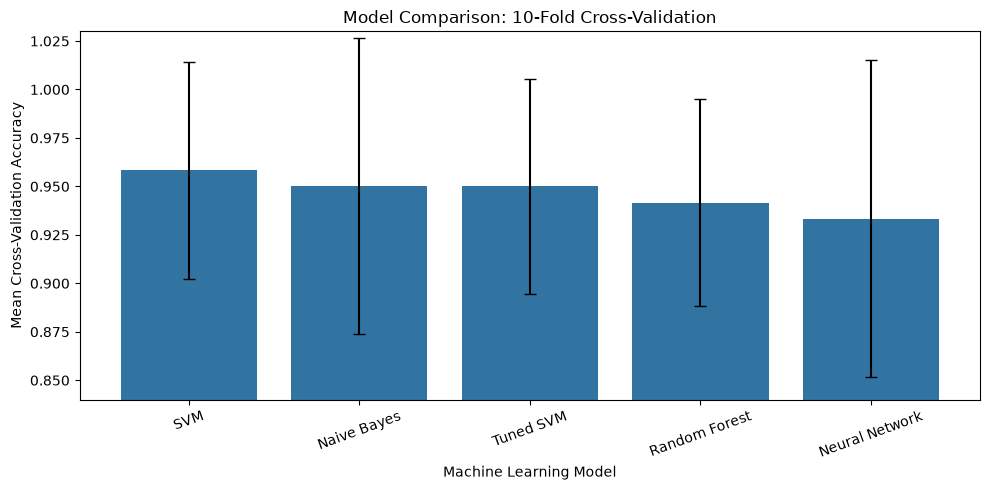

In [61]:
plt.figure(figsize=(10, 5))

sns.barplot(
    data=final_results,
    x='Model',
    y='Accuracy',
    errorbar=None
)

# Add error bars
plt.errorbar(
    x=np.arange(len(final_results)),
    y=final_results['Accuracy'],
    yerr=final_results['Accuracy SD'],
    fmt='none',
    color='black',
    capsize=4
)

plt.title('Model Comparison: 10-Fold Cross-Validation')
plt.xlabel('Machine Learning Model')
plt.ylabel('Mean Cross-Validation Accuracy')
plt.ylim(0.84, 1.03)
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

In [62]:
# Identify the best-performing model using cross-validation
best_model_name = final_results.loc[
    final_results['Accuracy'].idxmax(),
    'Model'
]

print("Best-performing model:", best_model_name)

# Select the appropriate model
if best_model_name == 'Tuned SVM':
    best_model = svm_grid
else:
    best_model = models[best_model_name]

# Fit the selected model on the full training dataset
best_model.fit(X_train, y_train)

# Display optimal SVM parameters if applicable
if best_model_name == 'Tuned SVM':
    print("Best parameters:", best_model.best_params_)

# Predict the held-out test observations
y_pred = best_model.predict(X_test)

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

# Calculate test metrics
test_metrics = pd.DataFrame([{
    'Accuracy': accuracy_score(y_test, y_pred),
    'Precision': precision_score(
        y_test, y_pred, average='macro'
    ),
    'Recall': recall_score(
        y_test, y_pred, average='macro'
    ),
    'F1-score': f1_score(
        y_test, y_pred, average='macro'
    )
}])

display(test_metrics.round(4))

# Classification report
print(classification_report(
    y_test,
    y_pred,
    zero_division=0
))

Best-performing model: SVM


,Accuracy,Precision,Recall,F1-score
0,0.9667,0.9697,0.9667,0.9666


                 precision    recall  f1-score   support

    Iris-setosa       1.00      1.00      1.00        10
Iris-versicolor       0.91      1.00      0.95        10
 Iris-virginica       1.00      0.90      0.95        10

       accuracy                           0.97        30
      macro avg       0.97      0.97      0.97        30
   weighted avg       0.97      0.97      0.97        30



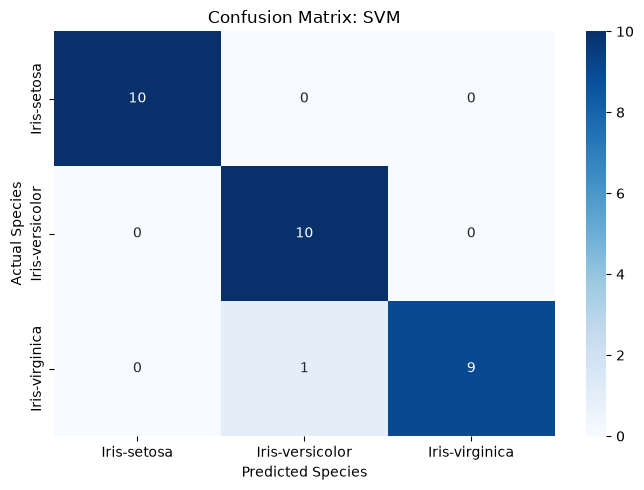

In [63]:
# Extract fitted estimator's class labels
if best_model_name == 'Tuned SVM':
    class_labels = best_model.best_estimator_.classes_
else:
    class_labels = best_model.classes_

# Create confusion matrix
cm = confusion_matrix(
    y_test,
    y_pred,
    labels=class_labels
)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=class_labels,
    yticklabels=class_labels
)

plt.title(f'Confusion Matrix: {best_model_name}')
plt.xlabel('Predicted Species')
plt.ylabel('Actual Species')
plt.tight_layout()
plt.show()

### Visual Relationships between the Features

,Sepal Length,Sepal Width,Petal Length,Petal Width
Class,,,,
Iris-setosa,5.01,3.42,1.46,0.24
Iris-versicolor,5.94,2.77,4.26,1.33
Iris-virginica,6.59,2.97,5.55,2.03


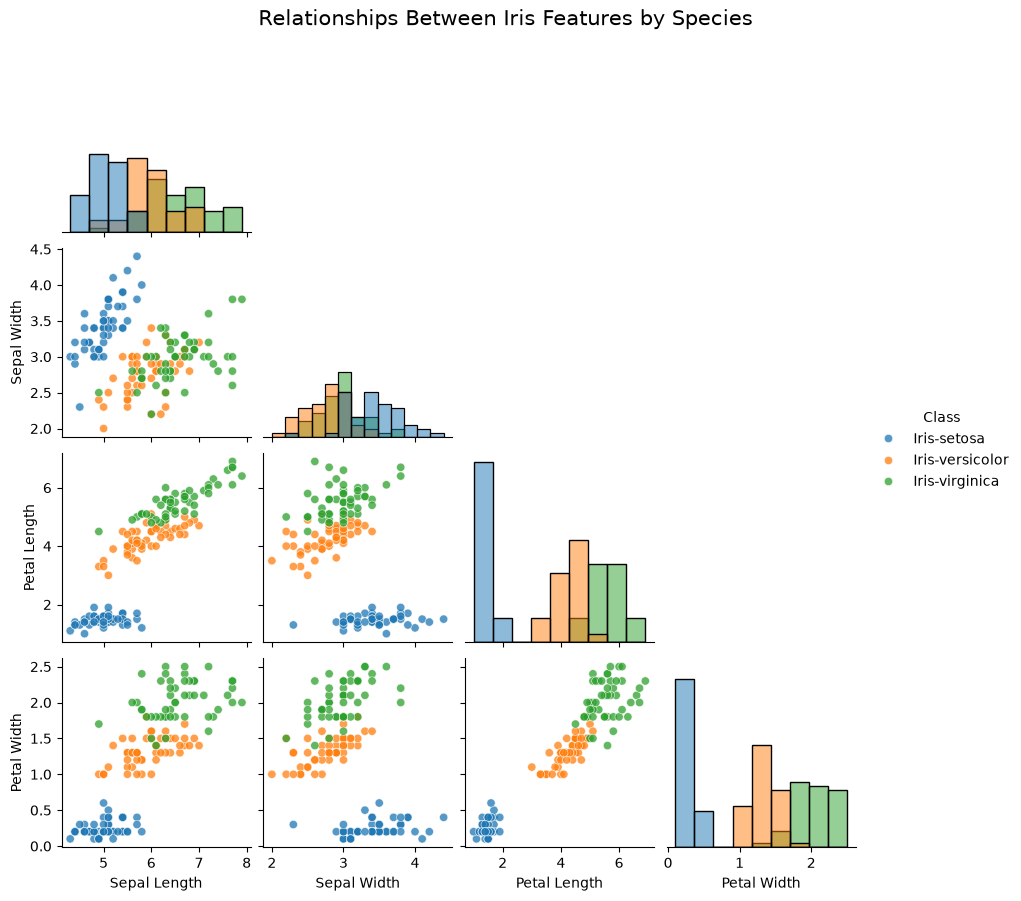

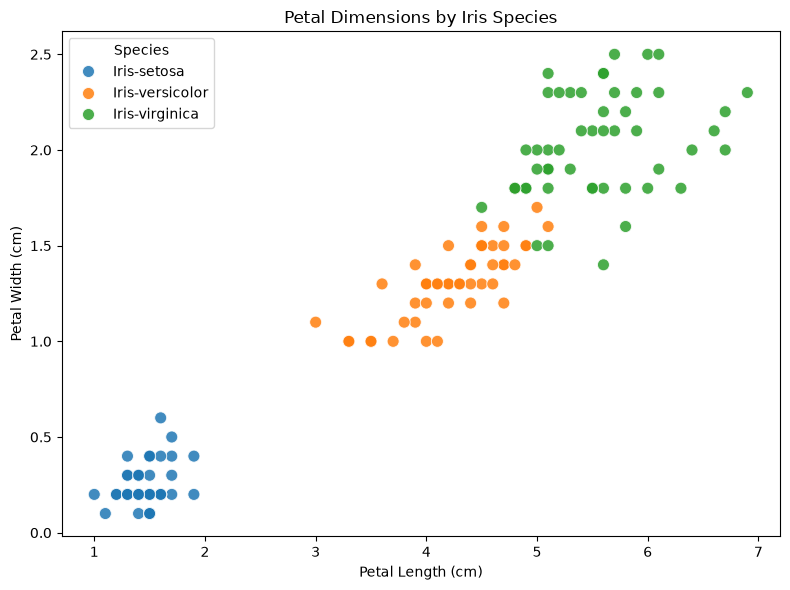

In [64]:
# Calculate mean feature measurements by species
species_means = iris_data.groupby('Class')[
    ['Sepal Length', 'Sepal Width',
     'Petal Length', 'Petal Width']
].mean()

display(species_means.round(2))

# Pairplot of explanatory variables
pair_plot = sns.pairplot(
    iris_data,
    hue='Class',
    diag_kind='hist',
    corner=True,
    height=2.2,
    plot_kws={'alpha': 0.75}
)

pair_plot.figure.suptitle(
    'Relationships Between Iris Features by Species',
    y=1.02,
    fontsize=15
)

plt.show()

plt.figure(figsize=(8, 6))

sns.scatterplot(
    data=iris_data,
    x='Petal Length',
    y='Petal Width',
    hue='Class',
    s=75,
    alpha=0.85
)

plt.title('Petal Dimensions by Iris Species')
plt.xlabel('Petal Length (cm)')
plt.ylabel('Petal Width (cm)')
plt.legend(title='Species')
plt.tight_layout()
plt.show()

### Additional Insight: Relationships Between Flower Characteristics

An additional analysis was conducted to investigate the relationships between the four explanatory variables and the Iris species.

The pairplot and petal-dimension scatterplot reveal that petal length and petal width are particularly useful for distinguishing between species.

Iris Setosa forms a clearly separated cluster, with considerably smaller petal measurements than the other species. Versicolor and Virginica exhibit larger petal dimensions and some overlap, although they remain reasonably distinguishable.

This suggests that petal measurements contain substantial predictive information about the species classification. In comparison, sepal measurements appear to provide less obvious separation between the three classes.

These findings help explain the predictive performance of the classification models. In particular, methods capable of identifying nonlinear relationships and complex decision boundaries may be effective when distinguishing between species with overlapping characteristics.

The analysis also demonstrates that not all explanatory variables contribute equally to classification. Petal length and width appear particularly informative, suggesting that feature selection or dimensionality reduction could be interesting directions for further investigation.